In [1]:
import myhda_ur as hda

In [2]:
hdata = hda.load_scifate()

In [3]:
top_hvg = hdata.get_highly_variable_genes(n=2000)

In [4]:
cells_hvg = hdata.get_timepoint_cells(n=100)     # 100 x 6tp = 600 cells

In [5]:
# Initialize a temporary subset object for the selected cells 
subset_cells_ = hdata[top_hvg, cells_hvg]    # 2000 genes x 600 cells

# Cell

## Total RNA

### Expression-distance clusters

gene x cell expression matrix -> distance matrix -> cluster 

In [6]:
# Compute cell-cell similarity of the selected cells using normalized gene expression values 
hdata.compute_similarity(
    data=subset_cells_,
    key="X",
    kind="cell",
    method="correlation"
)

sim_cells_ = hdata.similarities["correlation_X_cell"]

Similarity "correlation_X_cell" stored!


In [7]:
# Cluster the cells using Spectral Clustering
hdata.cluster_spectral(
        sim = sim_cells_,                                 
        kind = "cell",
        k = 6
    )

cl_spec_cells_ = hdata.clusters["spectral_k6_cell"]

Cluster "spectral_k6_cell" stored! 



In [8]:
# Get UMAP embeddings
hdata.reduce_UMAP(
    data = subset_cells_,
    key = "X",
    kind = "cell",
    id = "exp_dist"
)

em_cells_ = hdata.embeddings["umap_cell_exp_dist"]

UMAP embedding "umap_cell_exp_dist" stored! 



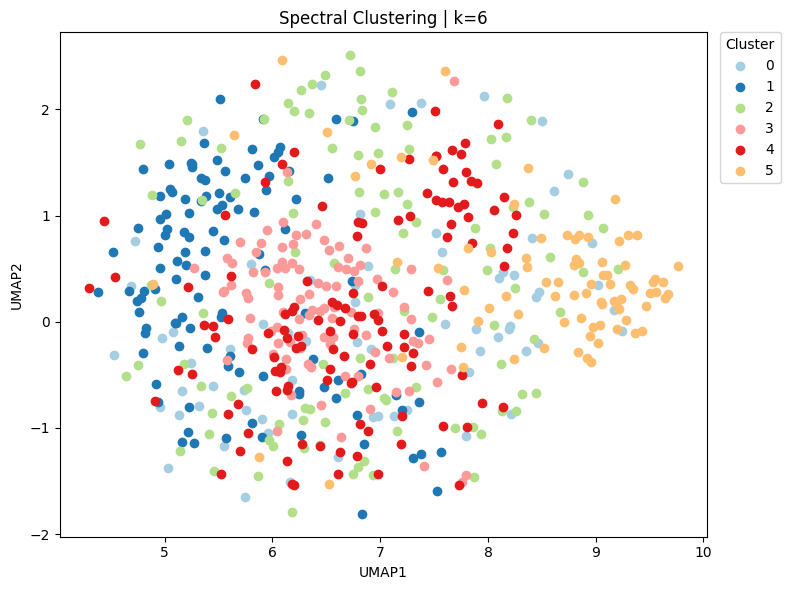

In [9]:
# Visualize 
hda.visualize.scatter(
    cluster=cl_spec_cells_,
    embedding=em_cells_,
    title="Spectral Clustering | k=6",
    show_label=False
)

### PCA-based clusters 

gene x cell expression matrix -> PCA (cell x PC) -> distance matrix -> cluster

In [6]:
# PCA for representation - cell x PC matrix
hdata.compute_PCA(
    data=subset_cells_,
    key="X",
    kind="cell",
    n_pc=20
)

PCA matrix cell x 20 PCs stored in HDAData.layers["pca_cell"] 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr', 'new_rna', 'pca_cell']
  similarities: []
  clusters: []
  embeddings: []
  trajectories: Yes

In [ ]:
# Compute cell-cell distance matrix in PC space
hdata.compute_similarity(
    data=subset_cells_,
    key="pca_cell",
    kind="cell",
    method="correlation"
)

Similarity "correlation_pca_cell_cell" stored! 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr', 'new_rna', 'pca_cell']
  similarities: ['correlation_pca_cell_cell']
  clusters: []
  embeddings: []
  trajectories: Yes

In [8]:
sim_pca_cells_ = hdata.similarities["correlation_pca_cell_cell"]   

In [9]:
# Cluster in PC space
hdata.cluster_spectral(
    sim=sim_pca_cells_,
    kind="cell",
    k=6
)

cl_pca_cells_ = hdata.clusters["spectral_k6_cell"]

Cluster "spectral_k6_cell" stored! 



In [10]:
# Get UMAP embeddings
hdata.reduce_UMAP(
    data=subset_cells_,
    key="pca_cell",
    kind="cell",
    id="pc20"
)

UMAP embedding "umap_cell_pc20" stored! 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr', 'new_rna', 'pca_cell']
  similarities: ['correlation_pca_cell_cell']
  clusters: ['spectral_k6_cell']
  embeddings: ['umap_cell_pc20']
  trajectories: Yes

In [11]:
em_pca_cells_ = hdata.embeddings["umap_cell_pc20"]

#### PC = 20

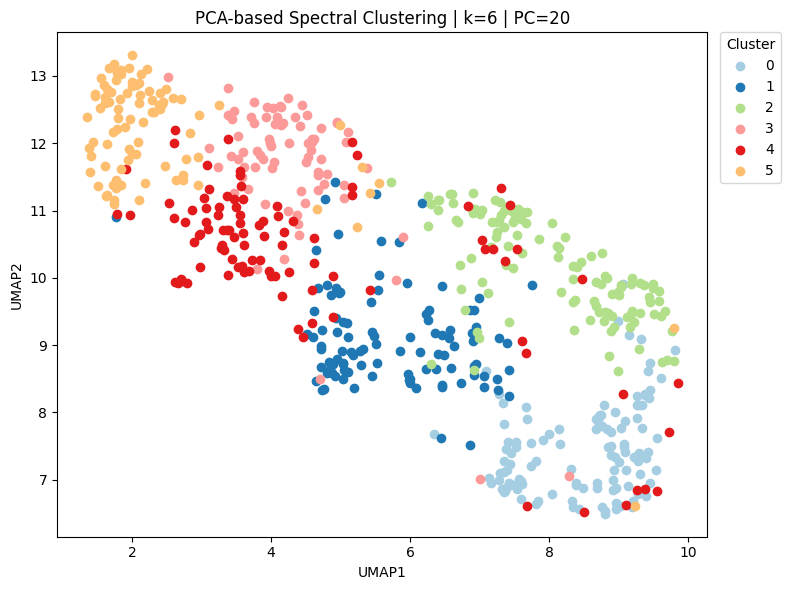

In [16]:
# Visualize 
hda.visualize.scatter(
    cluster=cl_pca_cells_,
    embedding=em_pca_cells_,
    title="PCA-based Spectral Clustering | k=6 | PC=20",
    show_label=False
)

#### PC = 5

PCA matrix cell x 5 PCs stored in HDAData.layers["pca_cell"] 

Similarity "correlation_pca_cell_cell" stored!
Cluster "spectral_k6_cell" stored! 

UMAP embedding "umap_cell_pc5" stored! 



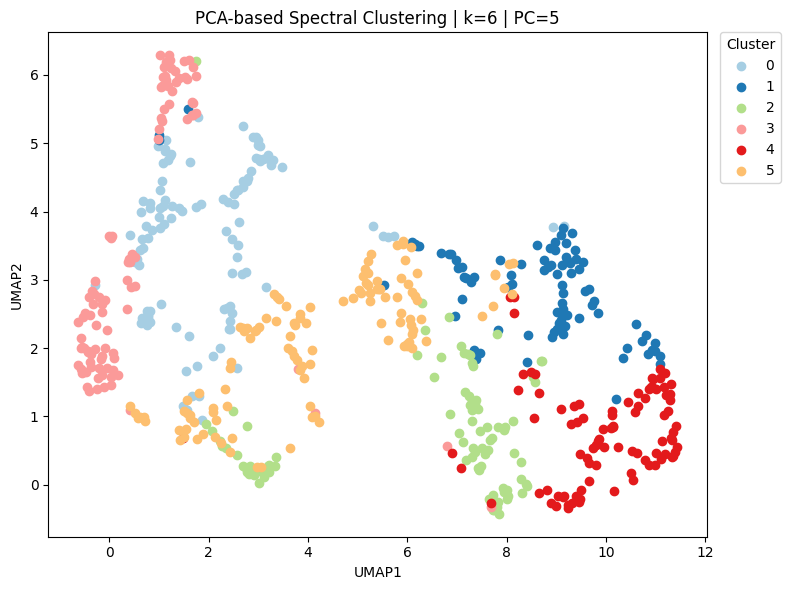

In [17]:
# PCA for representation - cell x PC matrix
hdata.compute_PCA(
    data=subset_cells_,
    key="X",
    kind="cell",
    n_pc=5
)

# Compute cell-cell distance matrix in PC space
hdata.compute_similarity(
    data=subset_cells_,
    key="pca_cell",
    kind="cell",
    method="correlation"
)

sim1 = hdata.similarities["correlation_pca_cell_cell"]   

# Cluster in PC space
hdata.cluster_spectral(
    sim=sim1,
    kind="cell",
    k=6
)

cl1= hdata.clusters["spectral_k6_cell"]

# Get UMAP embeddings
hdata.reduce_UMAP(
    data=subset_cells_,
    key="pca_cell",
    kind="cell",
    id="pc5"
)

em1= hdata.embeddings["umap_cell_pc5"]

# Visualize 
hda.visualize.scatter(
    cluster=cl1,
    embedding=em1,
    title="PCA-based Spectral Clustering | k=6 | PC=5",
    show_label=False
)

#### PC = 50

In [ ]:
# PCA for representation - cell x PC matrix
hdata.compute_PCA(
    data=subset_cells_,
    key="X",
    kind="cell",
    n_pc=50
)

pc_matrix = hdata.layers["pca"]    

# Compute cell-cell distance matrix in PC space
hdata.compute_similarity(
    data=subset_cells_,
    key="pca",
    method="correlation"
)

sim2 = hdata.similarities["correlation_pca_cell"]  

# Cluster in PC space
hdata.cluster_spectral(
    sim=sim2,
    kind="cell",
    k=6
)

cl2 = hdata.clusters["spectral_k6_cell"]

# Get UMAP embeddings
hdata.reduce_UMAP(
    key = "pca",
    kind = "cell",
    id = "pc50"
)

em2= hdata.embeddings["umap_cell_pc50"] 

# Visualize 
hda.visualize.scatter(
    cluster=cl2,
    embedding=em2,
    title="PCA-based Spectral Clustering | k=6 | PC=50",
    show_label=False
)

PCA matrix cell x 50 PCs stored in HDAData.layers["pca_cell"] 

Similarity "correlation_pca_cell_cell" stored!
Cluster "spectral_k6_cell" stored! 

UMAP embedding "umap_cell_pc50" stored! 



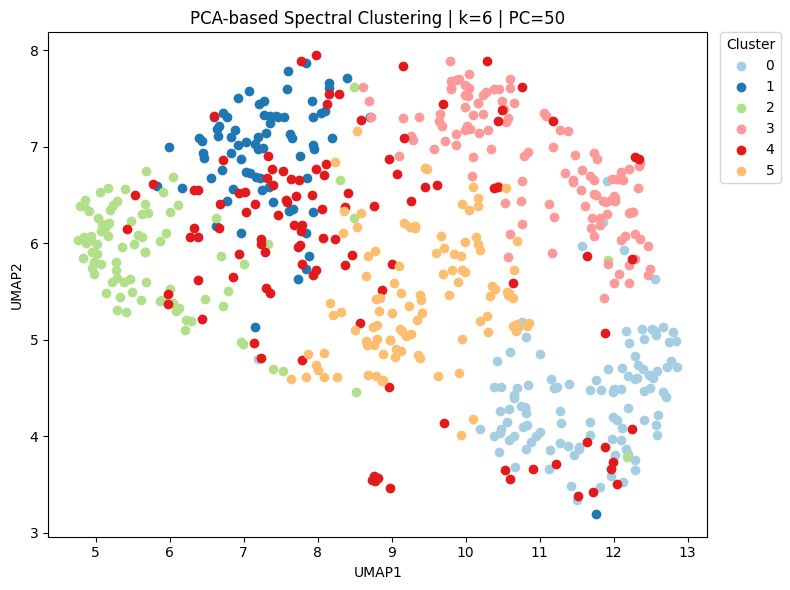

In [18]:
# PCA for representation - cell x PC matrix
hdata.compute_PCA(
    data=subset_cells_,
    key="X",
    kind="cell",
    n_pc=50
)

# Compute cell-cell distance matrix in PC space
hdata.compute_similarity(
    data=subset_cells_,
    key="pca_cell",
    kind="cell",
    method="correlation"
)

sim2 = hdata.similarities["correlation_pca_cell_cell"]   

# Cluster in PC space
hdata.cluster_spectral(
    sim=sim2,
    kind="cell",
    k=6
)

cl2= hdata.clusters["spectral_k6_cell"]

# Get UMAP embeddings
hdata.reduce_UMAP(
    data=subset_cells_,
    key="pca_cell",
    kind="cell",
    id="pc50"
)

em2= hdata.embeddings["umap_cell_pc50"]

# Visualize 
hda.visualize.scatter(
    cluster=cl2,
    embedding=em2,
    title="PCA-based Spectral Clustering | k=6 | PC=50",
    show_label=False
)

### Compare different PC

![img5](temp/img5.jpg)

## New RNA

#### PC = 20

PCA matrix cell x 20 PCs stored in HDAData.layers["pca_cell"] 

Similarity "correlation_pca_cell_cell" stored!
Cluster "spectral_k6_cell" stored! 

UMAP embedding "umap_cell_pc20" stored! 



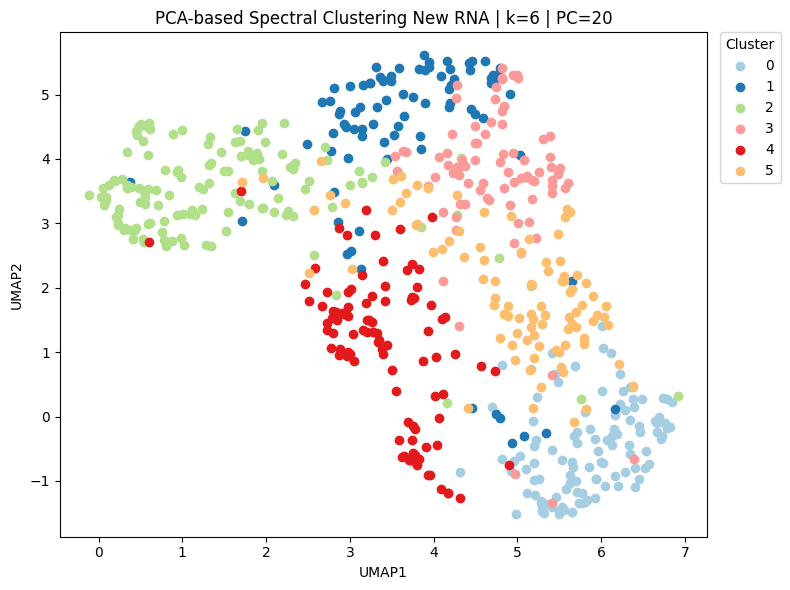

In [20]:
# PCA on new RNA
hdata.compute_PCA(
    data=subset_cells_,
    key="new_rna",      
    kind="cell",
    n_pc=20
)

pc_matrix = hdata.layers["pca_cell"]  

# Compute cell-cell distance matrix in PC space
hdata.compute_similarity(
    data=subset_cells_,
    key="pca_cell",
    kind="cell",
    method="correlation"
)

sim_pca_newrna_ = hdata.similarities["correlation_pca_cell_cell"]   

# Cluster in PC space
hdata.cluster_spectral(
    sim=sim_pca_newrna_,
    kind="cell",
    k=6
)

cl_pca_newrna_ = hdata.clusters["spectral_k6_cell"]

# Get UMAP embeddings
hdata.reduce_UMAP(
    data=subset_cells_,
    key="pca_cell",
    kind="cell",
    id = "pc20"
)

em_pca_newrna_= hdata.embeddings["umap_cell_pc20"] 

# Visualize 
hda.visualize.scatter(
    cluster=cl_pca_newrna_,
    embedding=em_pca_newrna_,
    title="PCA-based Spectral Clustering New RNA | k=6 | PC=20",
    show_label=False
)

### Compare Total RNA vs New RNA

![img6](temp/img6.jpg)